Calvin Woehrle
6/30/2026

Interpret a 4D fMRI run produced by dcm2niix.

Loads a NIfTI BOLD series makes random cool looking images


In [1]:

from pathlib import Path
from typing import cast

import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np
from nibabel.nifti1 import Nifti1Image
from nilearn import plotting
from nilearn.image import mean_img

NIIX_DIR = Path("niix")

def load(path: Path) -> Nifti1Image:
    return cast(Nifti1Image, nib.load(path))

In [2]:
# run = pick_run()
run = Path("niix/ep2d_AV_Semantics1_7.nii")


img = load(run)
data = img.get_fdata()  # shape (X, Y, Z, T)
zooms = img.header.get_zooms()
tr = float(zooms[3]) if len(zooms) > 3 else None

print(f"File:        {run.name}")
print(f"Shape:       {img.shape}  (X, Y, Z, time)")
print(f"Voxel size:  {tuple(round(z, 2) for z in zooms[:3])} mm")
print(f"TR:          {tr} s")
print(f"Volumes:     {img.shape[3] if img.ndim == 4 else 1}")
print(f"Duration:    {round(img.shape[3] * tr, 1) if tr else '?'} s")

if img.ndim != 4:
    print("Not a 4D series -- nothing temporal to interpret.")
    exit()

File:        ep2d_AV_Semantics1_7.nii
Shape:       (96, 96, 72, 168)  (X, Y, Z, time)
Voxel size:  (np.float32(2.0), np.float32(2.0), np.float32(2.0)) mm
TR:          2.0 s
Volumes:     168
Duration:    336.0 s


## Plot Anatomical

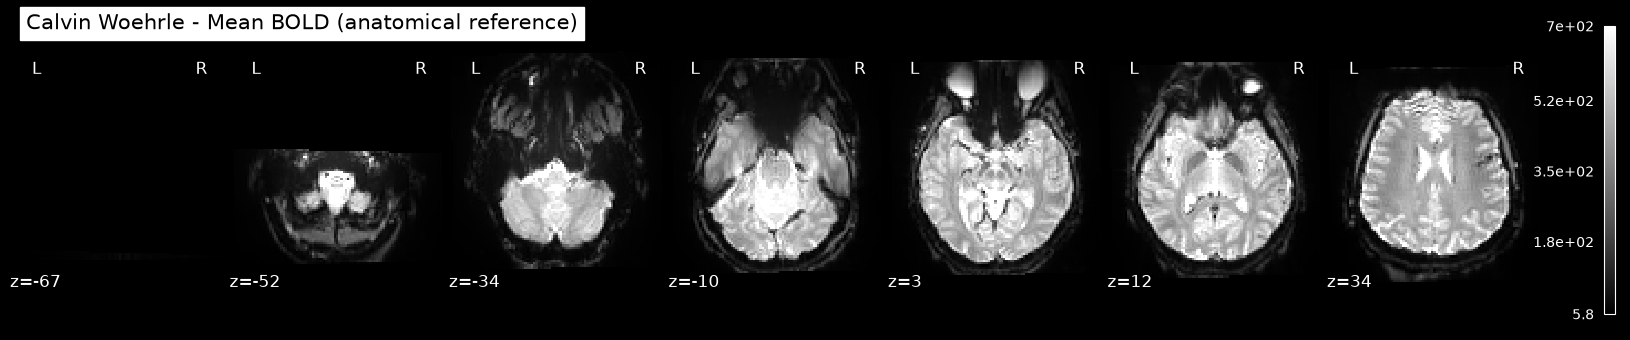

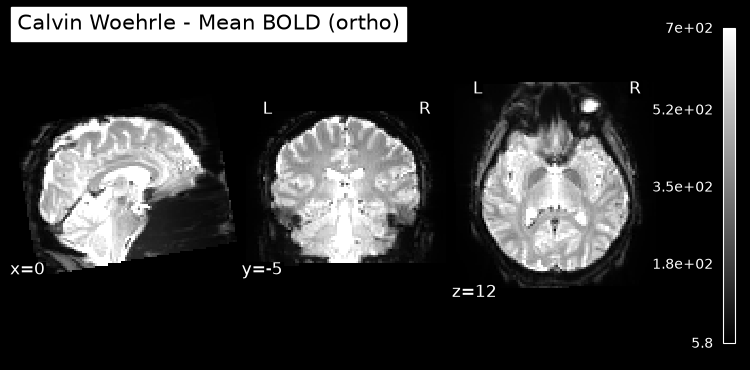

In [3]:
# An "anatomical" reference is best built from the MEAN BOLD volume,
# not the temporal SD map (which is dark inside the brain and noisy at edges).
mean_vol = data.mean(axis=3)
anat_nii = nib.Nifti1Image(mean_vol, img.affine, img.header)

# Robust intensity range so faint tissue isn't washed out by a few bright voxels.
vmin, vmax = np.percentile(mean_vol[mean_vol > 0], [2, 98])

# Axial montage: several slices through the brain in one figure.
plotting.plot_anat(
    anat_nii,
    title="Calvin Woehrle - Mean BOLD (anatomical reference)",
    display_mode="z",      # axial slices
    cut_coords=7,          # 7 evenly spaced slices
    vmin=vmin,
    vmax=vmax,
    draw_cross=False,
    annotate=True,
)

# Single ortho view (sagittal / coronal / axial) for orientation.
plotting.plot_anat(
    anat_nii,
    title="Calvin Woehrle - Mean BOLD (ortho)",
    display_mode="ortho",
    vmin=vmin,
    vmax=vmax,
    draw_cross=False,
)

plotting.show()


## Plot 1
Derived maps over the time dimension 

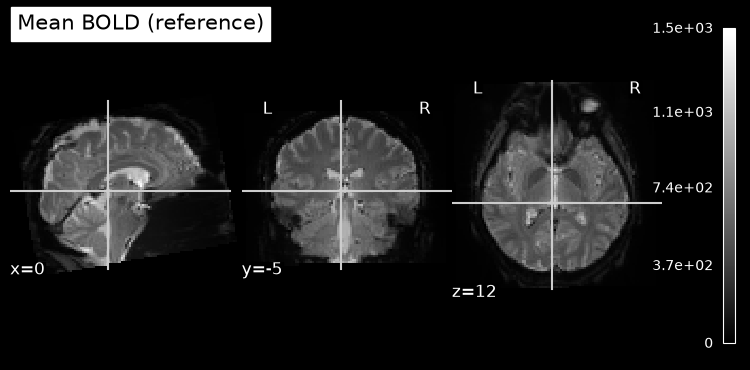

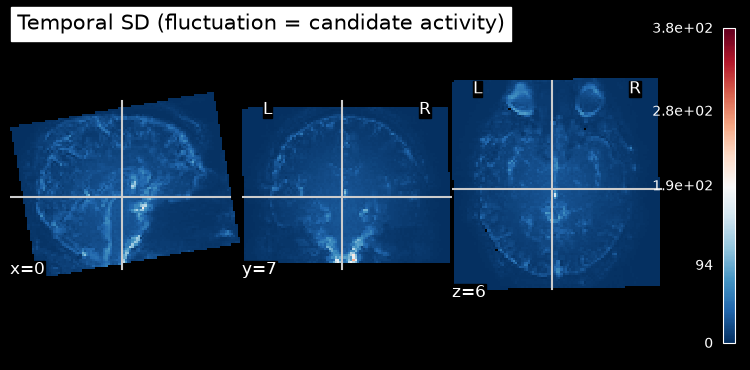

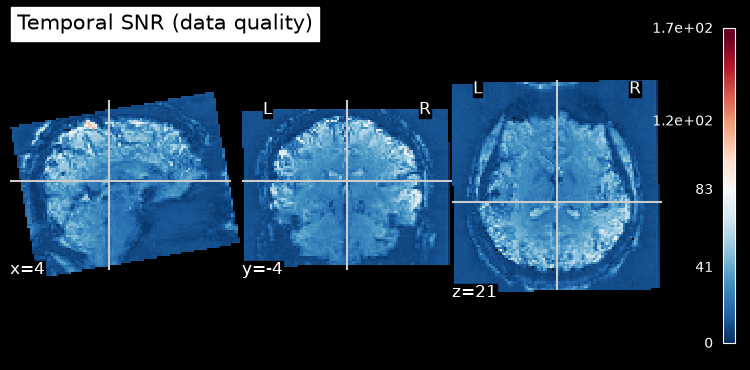

In [4]:
mean_vol = data.mean(axis=3)
std_vol = data.std(axis=3)

with np.errstate(divide="ignore", invalid="ignore"):
    tsnr = np.where(std_vol > 0, mean_vol / std_vol, 0)

mean_nii = mean_img(img)

std_nii = nib.Nifti1Image(std_vol, img.affine, img.header)

tsnr_nii = nib.Nifti1Image(tsnr, img.affine, img.header)

plotting.plot_epi(mean_nii, title="Mean BOLD (reference)")

plotting.plot_stat_map(
    std_nii, bg_img=mean_nii, title="Temporal SD (fluctuation = candidate activity)",
    colorbar=True
)
plotting.plot_stat_map(
    tsnr_nii, bg_img=mean_nii, title="Temporal SNR (data quality)", colorbar=True,
)

In [5]:
# --- Interactive sliders -------------------------------------------------
# Scroll through axial slices (Z) and time (volumes) of the raw 4D series.
%matplotlib inline
from ipywidgets import interact, IntSlider

nz = data.shape[2]
nt = data.shape[3]
vmin_d, vmax_d = np.percentile(data, [2, 98])


def show_slice(z=nz // 2, volume=0):
    plt.figure(figsize=(5, 5))
    plt.imshow(data[:, :, z, volume].T, cmap="gray", origin="lower",
               vmin=vmin_d, vmax=vmax_d)
    plt.title(f"z = {z}   volume = {volume}"
              f"   t = {volume * (tr or 1):.1f}s")
    plt.axis("off")
    plt.show()


interact(
    show_slice,
    z=IntSlider(min=0, max=nz - 1, step=1, value=nz // 2, description="Slice (z)"),
    volume=IntSlider(min=0, max=nt - 1, step=1, value=0, description="Volume (t)"),
)


interactive(children=(IntSlider(value=36, description='Slice (z)', max=71), IntSlider(value=0, description='Vo…

<function __main__.show_slice(z=36, volume=0)>

## Plot Min

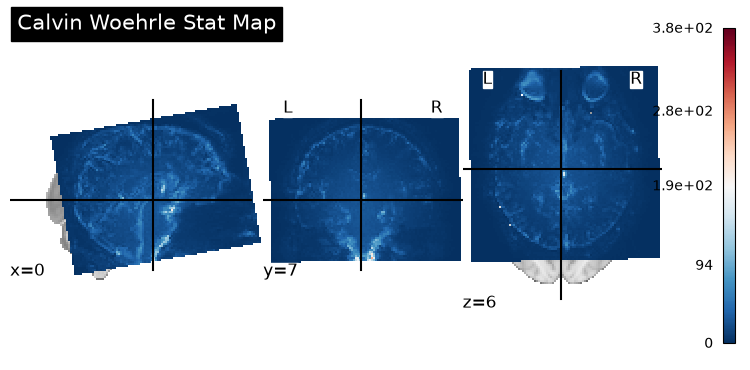

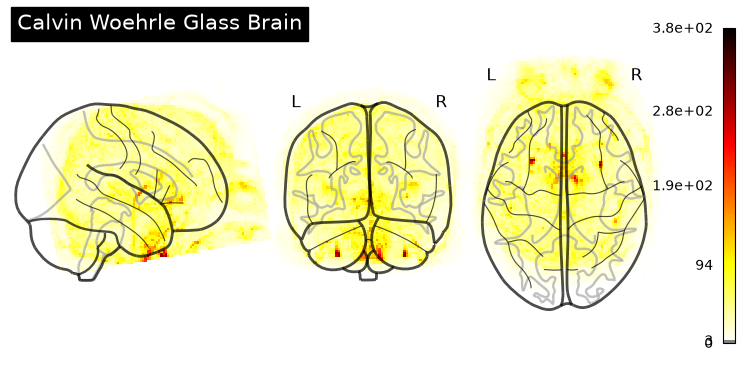

In [6]:
# mean_vol = data.mean(axis=3)
std_vol = data.std(axis=3)

# print(std_vol[1])

# print(img.affine)


std_nii = nib.Nifti1Image(std_vol, img.affine, img.header)


plotting.plot_stat_map(
    std_nii, title="Calvin Woehrle Stat Map",
    colorbar=True
)

plotting.plot_glass_brain(std_nii, threshold=3, title="Calvin Woehrle Glass Brain")

# with np.errstate(divide="ignore", invalid="ignore"):
#     tsnr = np.where(std_vol > 0, mean_vol / std_vol, 0)

# mean_nii = mean_img(img)

# std_nii = nib.Nifti1Image(std_vol, img.affine, img.header)

# tsnr_nii = nib.Nifti1Image(tsnr, img.affine, img.header)

# plotting.plot_epi(mean_nii, title="Mean BOLD (reference)")


# plotting.plot_stat_map(
#     tsnr_nii, bg_img=mean_nii, title="Temporal SNR (data quality)", colorbar=True,
# )

## Plot 2

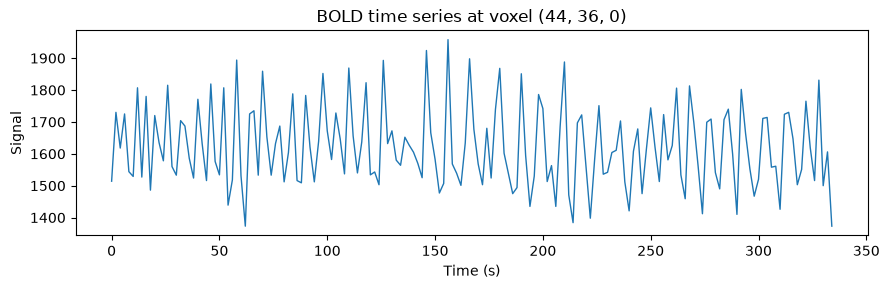

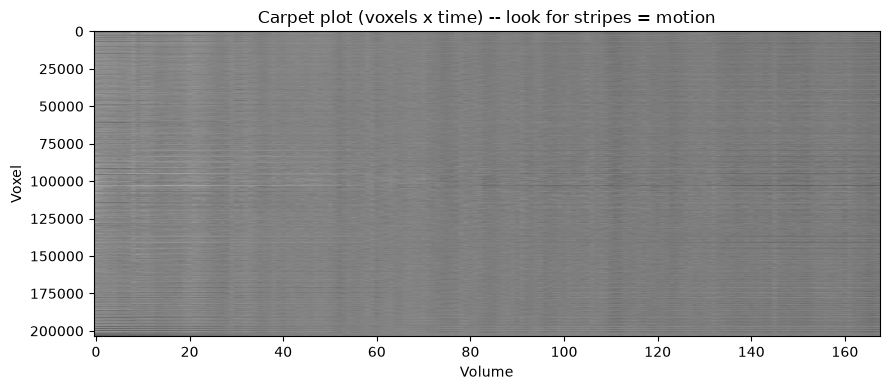

In [7]:


# --- One voxel's BOLD time series (the raw activity trace) -------------
# Pick the brightest in-brain voxel as an example.
cx, cy, cz = np.unravel_index(np.argmax(mean_vol), mean_vol.shape)
ts = data[cx, cy, cz, :]
t = np.arange(img.shape[3]) * (tr or 1)

fig, ax = plt.subplots(figsize=(9, 3))
# fig.suptitle(f"Voxel at ({cx}, {cy}, {cz}) -- mean signal = {mean_vol[cx, cy, cz]:.1f}")
ax.plot(t, ts, lw=1)
ax.set_title(f"BOLD time series at voxel ({cx}, {cy}, {cz})")
ax.set_xlabel("Time (s)" if tr else "Volume")
ax.set_ylabel("Signal")
fig.tight_layout()

# --- Carpet plot: every brain voxel over time -------------------------
brain = mean_vol > mean_vol.mean()  # crude brain mask
carpet = data[brain]  # (n_voxels, T)
carpet = (carpet - carpet.mean(axis=1, keepdims=True))  # detrend mean
fig2, ax2 = plt.subplots(figsize=(9, 4))
ax2.imshow(carpet, aspect="auto", cmap="gray", vmin=-50, vmax=50)
ax2.set_title("Carpet plot (voxels x time) -- look for stripes = motion")
ax2.set_xlabel("Volume")
ax2.set_ylabel("Voxel")
fig2.tight_layout()

plotting.show()
plt.show()